# N-Queens Problem — Genetic Algorithm + Animation

This notebook solves the **N-Queens problem** using a **Genetic Algorithm (GA)**  
and shows an animated visualisation of the board evolving across generations.

| Symbol | Meaning |
|--------|---------|
| 🟩 ♛  | Queen is **not** attacking any other queen |
| 🟥 ♛  | Queen **is** in conflict with at least one other queen |

> **No external files needed**

---

## 1 · Install dependencies

In [1]:
import sys
!{sys.executable} -m pip install matplotlib numpy ipython --quiet
print('Dependencies ready ✓')

Dependencies ready ✓


## 2 · Core module (inline)

Run this cell once — it defines all GA and animation functions.

In [2]:
# ════════════════════════════════════════════════════════════════
#  N-Queens — Genetic Algorithm  (self-contained inline module)
# ════════════════════════════════════════════════════════════════

import random
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

matplotlib.rcParams['animation.embed_limit'] = 50  # increase if needed (MB)

# ── Colours ──────────────────────────────────────────────────────
LIGHT_SQ     = '#F0D9B5'
DARK_SQ      = '#B58863'
ATTACK_COLOR = '#E74C3C'   # red  — queen is attacking
SAFE_COLOR   = '#27AE60'   # green — queen is safe


# ── 1. GA primitives ─────────────────────────────────────────────

def random_chromosome(n):
    """Permutation of [0..n-1]: chromosome[col] = row of queen in that column."""
    return random.sample(range(n), n)


def fitness(chromosome):
    """
    Count non-attacking pairs.
    Max = n*(n-1)//2  → perfect solution.
    Row collisions are impossible (permutation); only diagonals are checked.
    """
    n = len(chromosome)
    max_pairs = n * (n - 1) // 2
    attacking = sum(
        1
        for i in range(n)
        for j in range(i + 1, n)
        if abs(chromosome[i] - chromosome[j]) == abs(i - j)
    )
    return max_pairs - attacking


def select_parent(population, fitnesses):
    """Tournament selection with k=3."""
    contestants = random.sample(list(zip(fitnesses, population)), 3)
    return max(contestants, key=lambda x: x[0])[1]


def ordered_crossover(p1, p2):
    """Order-1 (OX) crossover — always produces a valid permutation."""
    n = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    child = [-1] * n
    child[a:b + 1] = p1[a:b + 1]
    ptr = 0
    for gene in p2:
        if gene not in child:
            while child[ptr] != -1:
                ptr += 1
            child[ptr] = gene
    return child


def mutate(chromosome, rate):
    """Swap mutation: exchange two random positions."""
    chrom = chromosome[:]
    if random.random() < rate:
        i, j = random.sample(range(len(chrom)), 2)
        chrom[i], chrom[j] = chrom[j], chrom[i]
    return chrom


# ── 2. Main GA loop ───────────────────────────────────────────────

def genetic_algorithm(
    n=8, pop_size=100, max_generations=1000,
    mutation_rate=0.1, elitism=5, seed=None
):
    """
    Run the genetic algorithm.

    Returns a dict:
      solution    : best chromosome found (None if unsolved)
      generations : list of best chromosomes per generation
      fitnesses   : list of best fitness values per generation
      max_fitness : n*(n-1)//2
      solved      : bool
      n           : board size
    """
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    max_fitness = n * (n - 1) // 2
    population  = [random_chromosome(n) for _ in range(pop_size)]
    best_per_gen, fit_per_gen = [], []
    solution = None

    for _ in range(max_generations):
        fits     = [fitness(c) for c in population]
        best_idx = int(np.argmax(fits))
        best_fit = fits[best_idx]

        best_per_gen.append(population[best_idx][:])
        fit_per_gen.append(best_fit)

        if best_fit == max_fitness:
            solution = population[best_idx][:]
            break

        # Elitism: keep top individuals unchanged
        sorted_pop = [c for _, c in sorted(zip(fits, population), key=lambda x: -x[0])]
        new_pop = sorted_pop[:elitism]

        while len(new_pop) < pop_size:
            child = mutate(
                ordered_crossover(
                    select_parent(population, fits),
                    select_parent(population, fits)
                ),
                mutation_rate
            )
            new_pop.append(child)

        population = new_pop

    return {
        'solution'   : solution,
        'generations': best_per_gen,
        'fitnesses'  : fit_per_gen,
        'max_fitness': max_fitness,
        'solved'     : solution is not None,
        'n'          : n,
    }


# ── 3. Board drawing ──────────────────────────────────────────────

def draw_board(ax, chromosome, n, generation, fitness_val, max_fitness):
    ax.clear()
    ax.set_aspect('equal')
    ax.axis('off')

    for row in range(n):
        for col in range(n):
            color = LIGHT_SQ if (row + col) % 2 == 0 else DARK_SQ
            ax.add_patch(mpatches.FancyBboxPatch(
                (col, row), 1, 1,
                boxstyle='square,pad=0',
                facecolor=color, edgecolor='none'
            ))

    # find attacking columns
    attacking = set()
    for i in range(n):
        for j in range(i + 1, n):
            if abs(chromosome[i] - chromosome[j]) == abs(i - j):
                attacking.add(i)
                attacking.add(j)

    for col, row in enumerate(chromosome):
        ax.text(
            col + 0.5, row + 0.5, '♛',
            ha='center', va='center',
            fontsize=max(10, 160 // n),
            color=ATTACK_COLOR if col in attacking else SAFE_COLOR,
            fontweight='bold',
        )

    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    pct    = int(100 * fitness_val / max_fitness)
    solved = fitness_val == max_fitness
    ax.set_title(
        f"Generation {generation}   |   {'✓ SOLVED!' if solved else f'Fitness: {fitness_val}/{max_fitness}  ({pct}%)'}",
        fontsize=13, fontweight='bold',
        color=SAFE_COLOR if solved else '#2C3E50',
        pad=10
    )


# ── 4. Animation builder ──────────────────────────────────────────

def animate_ga(result, interval=120, max_frames=200, fitness_panel=True):
    """
    Build a FuncAnimation from the GA result history.

    Parameters
    ----------
    result        : dict returned by genetic_algorithm()
    interval      : ms between frames
    max_frames    : cap on total frames (subsampled if needed)
    fitness_panel : show fitness-over-generations subplot
    """
    generations = result['generations']
    fitnesses   = result['fitnesses']
    max_fitness = result['max_fitness']
    n           = result['n']
    total       = len(generations)

    idx = (
        list(range(0, total - 1, total // max_frames)) + [total - 1]
        if total > max_frames else list(range(total))
    )

    if fitness_panel:
        fig, (ax_board, ax_fit) = plt.subplots(
            1, 2, figsize=(12, 6),
            gridspec_kw={'width_ratios': [1, 1]}
        )
    else:
        fig, ax_board = plt.subplots(1, 1, figsize=(6, 6))
        ax_fit = None

    fig.patch.set_facecolor('#FAFAFA')

    if ax_fit is not None:
        ax_fit.set_facecolor('#F7F7F7')
        ax_fit.set_xlabel('Generation', fontsize=11)
        ax_fit.set_ylabel('Best Fitness', fontsize=11)
        ax_fit.set_title('Fitness over Generations', fontsize=12, fontweight='bold')
        ax_fit.set_xlim(0, total)
        ax_fit.set_ylim(0, max_fitness + 0.5)
        ax_fit.axhline(max_fitness, color=SAFE_COLOR, lw=1.5, ls='--', label='Max fitness')
        ax_fit.legend(fontsize=9)
        line_fit, = ax_fit.plot([], [], color='#3498DB', lw=2)
        dot_fit,  = ax_fit.plot([], [], 'o', color='#E74C3C', ms=7)

    def update(frame_idx):
        i     = idx[frame_idx]
        chrom = generations[i]
        fit   = fitnesses[i]
        draw_board(ax_board, chrom, n, i + 1, fit, max_fitness)
        if ax_fit is not None:
            line_fit.set_data(list(range(i + 1)), fitnesses[:i + 1])
            dot_fit.set_data([i], [fit])
        return [ax_board] + ([line_fit, dot_fit] if ax_fit else [])

    anim = FuncAnimation(fig, update, frames=len(idx), interval=interval, blit=False)
    plt.tight_layout()
    return anim


# ── 5. One-liner helper ───────────────────────────────────────────

def solve_and_animate(
    n=8, pop_size=150, max_generations=2000,
    mutation_rate=0.15, elitism=5, seed=42,
    interval=100, max_frames=200
):
    """
    Run GA then return an HTML animation for Jupyter.

    Example
    -------
    >>> solve_and_animate(n=8)
    """
    print(f'Running GA for {n}-Queens …')
    result = genetic_algorithm(
        n=n, pop_size=pop_size, max_generations=max_generations,
        mutation_rate=mutation_rate, elitism=elitism, seed=seed
    )
    if result['solved']:
        print(f"✓ Solution found in generation {len(result['generations'])}!")
        print(f"  Chromosome: {result['solution']}")
    else:
        print(f"✗ No solution after {len(result['generations'])} generations."
              f" Best fitness: {max(result['fitnesses'])}/{result['max_fitness']}")
    anim = animate_ga(result, interval=interval, max_frames=max_frames)
    return HTML(anim.to_jshtml())


print('✓ All functions defined — ready to run!')

✓ All functions defined — ready to run!


---
## 3 · Quick start — one-liner

Call `solve_and_animate(n=8)` to run everything and display the animation inline.

Running GA for 8-Queens …
✓ Solution found in generation 5!
  Chromosome: [5, 3, 0, 4, 7, 1, 6, 2]


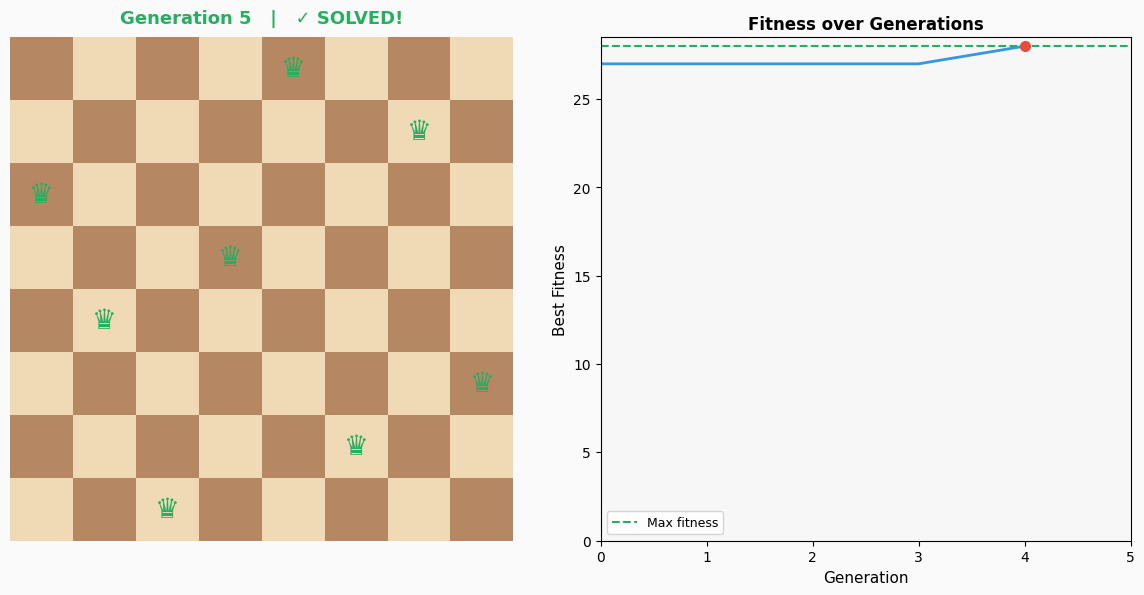

In [3]:
# 8-Queens (classic) — typically solves in < 1 second
solve_and_animate(n=8, seed=42)

---
## 4 · Custom run — step by step

Use `genetic_algorithm()` and `animate_ga()` separately for full control.

In [4]:
# ── Hyperparameters ────────────────────────────────────
N             = 12       # board size (try 8, 10, 12, 16)
POP_SIZE      = 200      # individuals per generation
MAX_GENS      = 3000     # maximum generations
MUTATION_RATE = 0.15     # swap-mutation probability
ELITISM       = 10       # top individuals carried unchanged
SEED          = 7        # None = random each run
# ───────────────────────────────────────────────────────

result = genetic_algorithm(
    n=N, pop_size=POP_SIZE, max_generations=MAX_GENS,
    mutation_rate=MUTATION_RATE, elitism=ELITISM, seed=SEED,
)

total_gens = len(result['generations'])
if result['solved']:
    print(f'✓ Solved in generation {total_gens}!')
    print(f"  Solution: {result['solution']}")
else:
    print(f'✗ Best fitness after {total_gens} generations: '
          f"{max(result['fitnesses'])}/{result['max_fitness']}")

✓ Solved in generation 19!
  Solution: [8, 4, 0, 9, 5, 2, 11, 6, 3, 1, 10, 7]


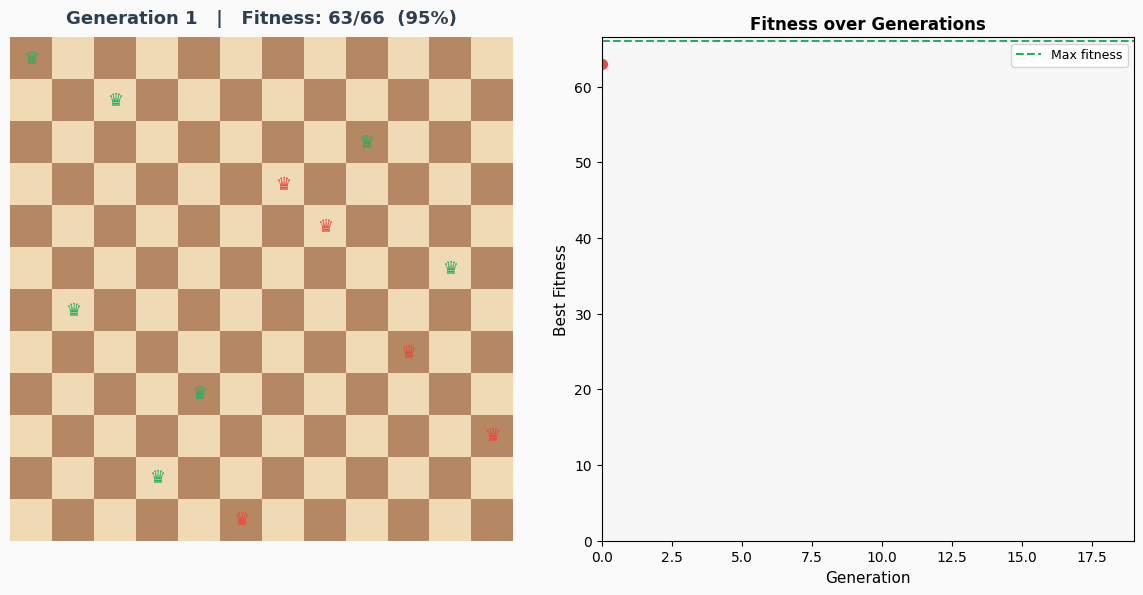

In [5]:
# Animate the custom run (may take ~10 s to render for large boards)
anim = animate_ga(
    result,
    interval=120,       # ms per frame
    max_frames=200,     # subsamples if GA ran longer
    fitness_panel=True, # show fitness graph alongside board
)
HTML(anim.to_jshtml())

---
## 5 · Fitness curve (static plot)

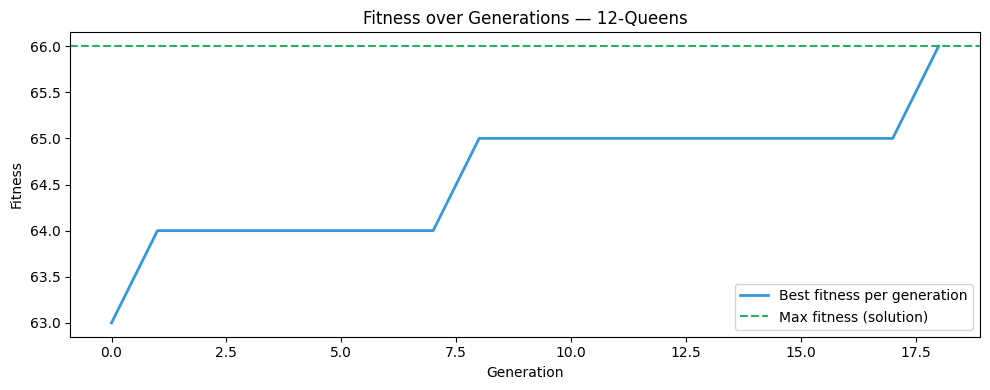

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(result['fitnesses'], color='#3498DB', lw=2, label='Best fitness per generation')
plt.axhline(result['max_fitness'], color='#27AE60', ls='--', lw=1.5, label='Max fitness (solution)')
plt.xlabel('Generation')
plt.ylabel('Fitness')
plt.title(f'Fitness over Generations — {N}-Queens')
plt.legend()
plt.tight_layout()
plt.show()

---
## 6 · Experiment — compare board sizes

In [7]:
import time

sizes = [6, 8, 10, 12]
print(f"{'N':>4}  {'Solved':>7}  {'Generations':>12}  {'Time (s)':>10}")
print('-' * 40)
for sz in sizes:
    t0 = time.time()
    r  = genetic_algorithm(n=sz, pop_size=200, max_generations=3000,
                           mutation_rate=0.15, elitism=10, seed=42)
    elapsed = time.time() - t0
    print(f"{sz:>4}  {str(r['solved']):>7}  "
          f"{len(r['generations']):>12}  {elapsed:>10.2f}")

   N   Solved   Generations    Time (s)
----------------------------------------
   6     True             1        0.00
   8     True             2        0.01
  10     True            14        0.09
  12     True            10        0.07


---
## 7 · Save animation as GIF (optional)

GIF saved.


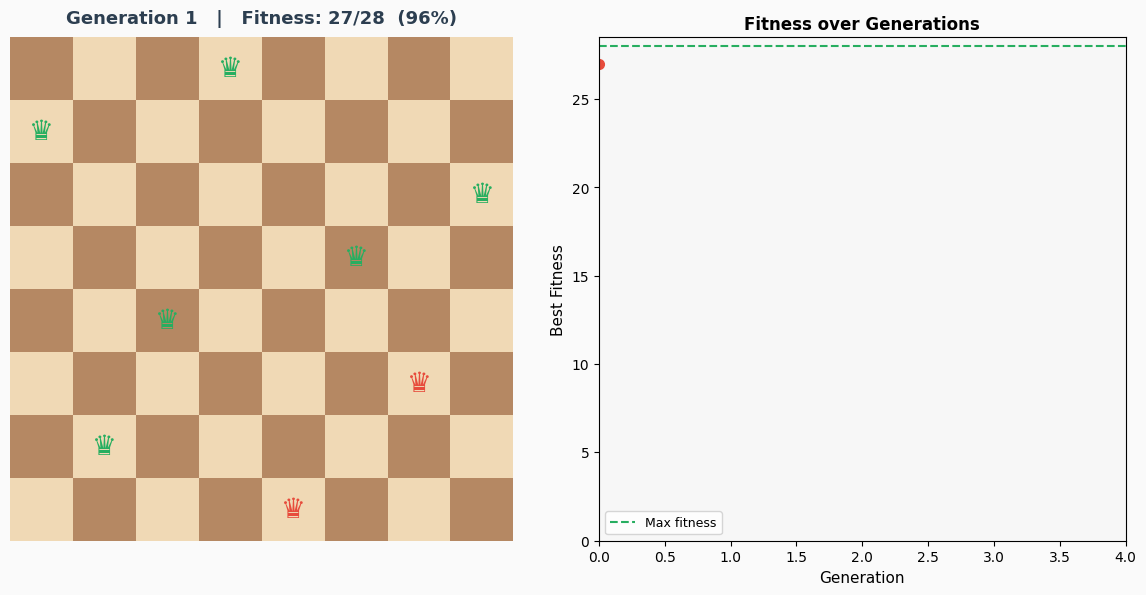

In [10]:
!pip install pillow
# Uncomment to save:

result8 = genetic_algorithm(n=8, seed=42)
anim8   = animate_ga(result8, interval=100, max_frames=150)
anim8.save('nqueens_solution.gif', writer='pillow', fps=10)
print('GIF saved.')